In [2]:
!pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 2.6 MB/s eta 0:00:17
   - -------------------------------------- 1.8/44.0 MB 4.2 MB/s eta 0:00:11
   -- ------------------------------------- 2.9/44.0 MB 4.9 MB/s eta 0:00:09
   ----- ---------------------------------- 5.8/44.0 MB 6.5 MB/s eta 0:00:06
   ------- -------------------------------- 7.9/44.0 MB 7.4 MB/s eta 0:00:05
   --------- ------------------------------ 10.2/44.0 MB 8.0 MB/s eta 0:00:05
   ----------- ---------------------------- 12.3/44.0 MB 8.3 MB/s eta 0:00:04
   ------------- -------------------------- 14.7/44.0 MB 8.6 MB/s eta 0:00:04
   --------------- ------------------------ 17.0/44.0 MB 8.9 MB/s eta 0:00:04
   ----------------- ---------------------- 19.4/44.0 MB 9.1 MB/s eta 0:00:03
   ------------

  You can safely remove it manually.
ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\Kanakan\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np

import cv2

In [2]:
import sys
print(sys.executable)

C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\python.exe


In [3]:
import sys
import numpy as np
import cv2

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("OpenCV version:", cv2.__version__)

Python executable: C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\python.exe
Python version: 3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]
NumPy version: 2.4.6
OpenCV version: 4.11.0


In [4]:
# Data handling
import os
from pathlib import Path
import pandas as pd
import numpy as np

# Image processing
import cv2

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:

DATASET_DIR = Path(r"C:\Users\Kanakan\Skin Lesion Classification\PAD-UFES Dataset")

In [6]:
# Image folders
IMAGE_DIRS = [
    DATASET_DIR / "imgs_part_1" / "imgs_part_1",
    DATASET_DIR / "imgs_part_2" / "imgs_part_2",
    DATASET_DIR / "imgs_part_3" / "imgs_part_3"
]

# Metadata CSV
CSV_PATH = DATASET_DIR / "metadata.csv"

# Check whether all paths exist
for folder in IMAGE_DIRS:
    print(folder.name, ":", folder.exists())

print("Metadata CSV:", CSV_PATH.exists())

imgs_part_1 : True
imgs_part_2 : True
imgs_part_3 : True
Metadata CSV: True


**Our image EDA will focus on:**
- Number of images and their distribution across the three folders.
- Image dimensions and resolution.
- Sample image visualisation.
- Pixel intensity, brightness and contrast.
- Image quality and corrupted files.
- Duplicate images.

In [7]:
image_files = []


for folder in IMAGE_DIRS:
    folder_images = list(folder.glob("*.png"))
    image_files.extend(folder_images)

    print(f"{folder.name}: {len(folder_images)} images")

print("\nTotal PNG images:", len(image_files))

imgs_part_1: 911 images
imgs_part_2: 659 images
imgs_part_3: 728 images

Total PNG images: 2298


In [8]:
# Store basic image information
image_info = []

for image_path in image_files:

    image = cv2.imread(str(image_path))

    if image is not None:
        height, width, channels = image.shape

        image_info.append({
            "filename": image_path.name,
            "width": width,
            "height": height,
            "channels": channels,
            "file_size_kb": image_path.stat().st_size / 1024
        })

# Convert to DataFrame
image_df = pd.DataFrame(image_info)

print("Successfully read images:", len(image_df))
print("Unreadable images:", len(image_files) - len(image_df))

display(image_df.head())

Successfully read images: 2298
Unreadable images: 0


,filename,width,height,channels,file_size_kb
0,PAT_100_393_595.png,394,394,3,202.843750
1,PAT_100_393_898.png,221,221,3,75.393555
2,PAT_101_1041_651.png,1131,1131,3,1765.536133
3,PAT_101_1041_658.png,741,740,3,822.568359
4,PAT_101_1041_898.png,1795,1796,3,4882.708984


In [9]:
print("Image dimension statistics:")

display(
    image_df[["width", "height", "channels", "file_size_kb"]].describe()
)

Image dimension statistics:


,width,height,channels,file_size_kb
count,2298.000000,2298.000000,2298.0,2298.000000
mean,933.679721,933.605309,3.0,1532.639485
std,534.598513,534.668475,0.0,1717.018689
min,147.000000,147.000000,3.0,36.581055
25%,528.000000,527.250000,3.0,435.087646
50%,779.500000,779.500000,3.0,934.603516
75%,1219.250000,1218.750000,3.0,2004.163574
max,3474.000000,3476.000000,3.0,23064.569336


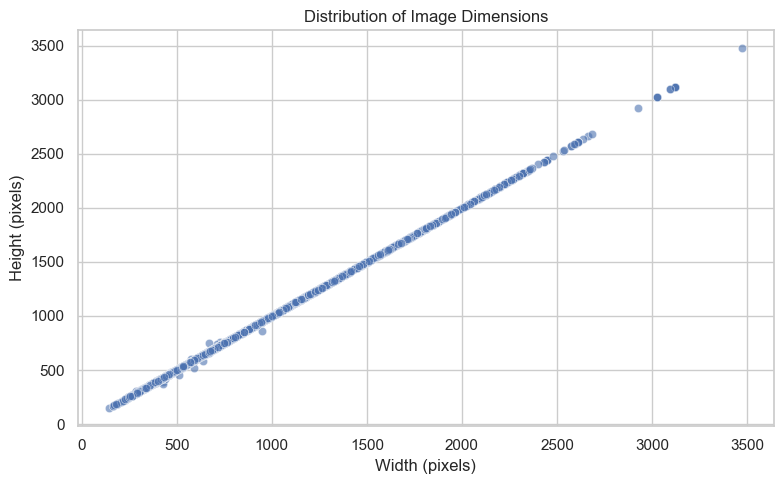

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=image_df,
    x="width",
    y="height",
    alpha=0.6
)

plt.title("Distribution of Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")

plt.tight_layout()
plt.show()

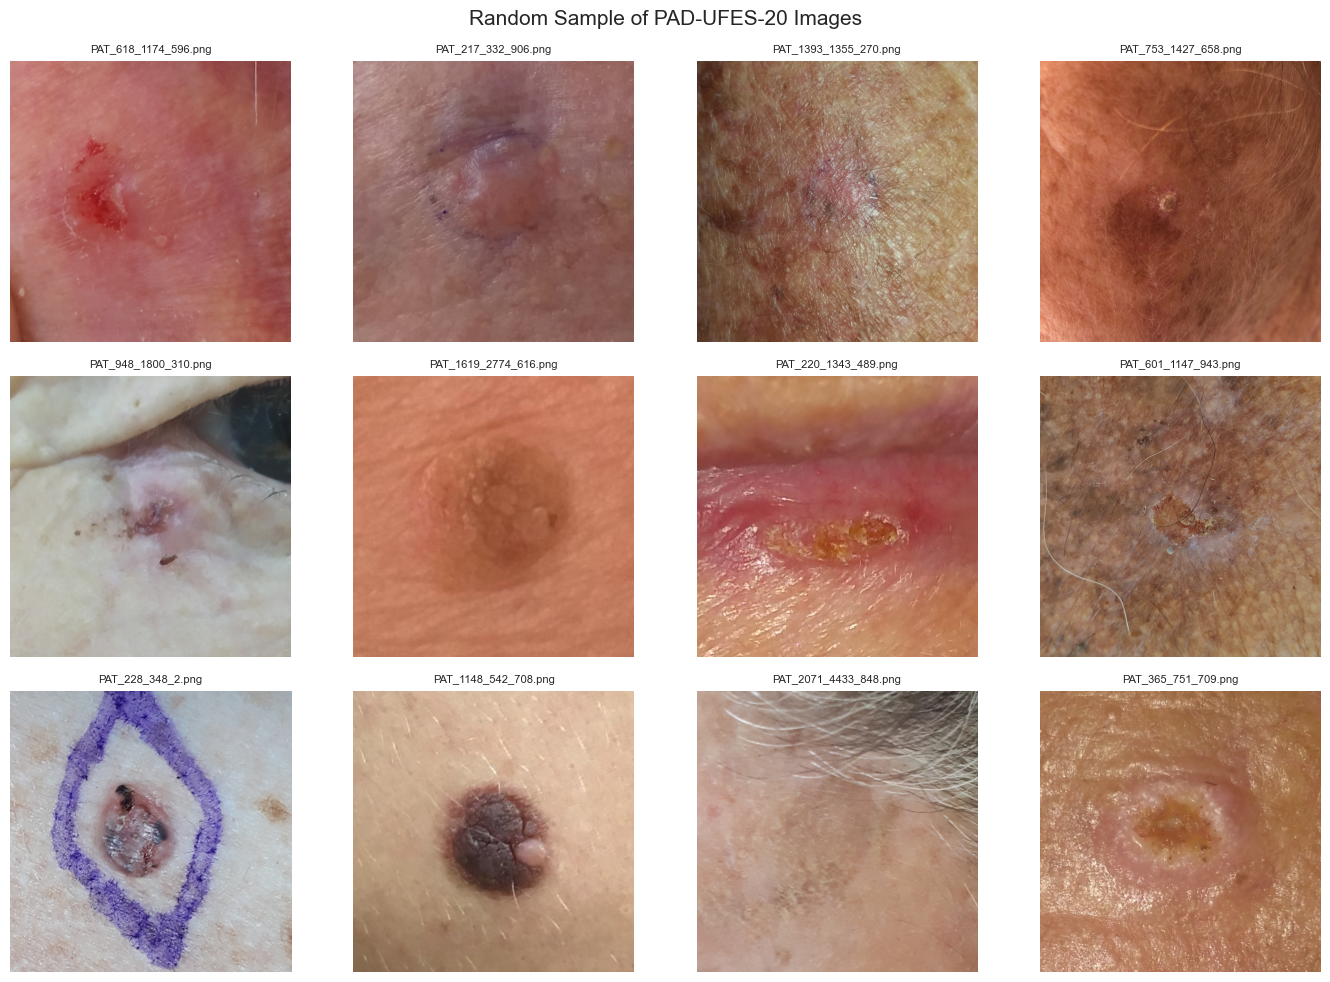

In [11]:
# Select 12 random images
sample_images = np.random.default_rng(42).choice(
    image_files,
    size=min(12, len(image_files)),
    replace=False
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, image_path in zip(axes.flatten(), sample_images):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(image_path.name, fontsize=8)
    ax.axis("off")

plt.suptitle("Random Sample of PAD-UFES-20 Images", fontsize=15)
plt.tight_layout()
plt.show()

The dataset contains images with considerable variation in spatial resolution, which makes image resizing an important preprocessing requirement before CNN training.

count    2298.000000
mean        1.000189
std         0.007153
min         0.888446
25%         1.000000
50%         1.000000
75%         1.000000
max         1.156757
Name: aspect_ratio, dtype: float64

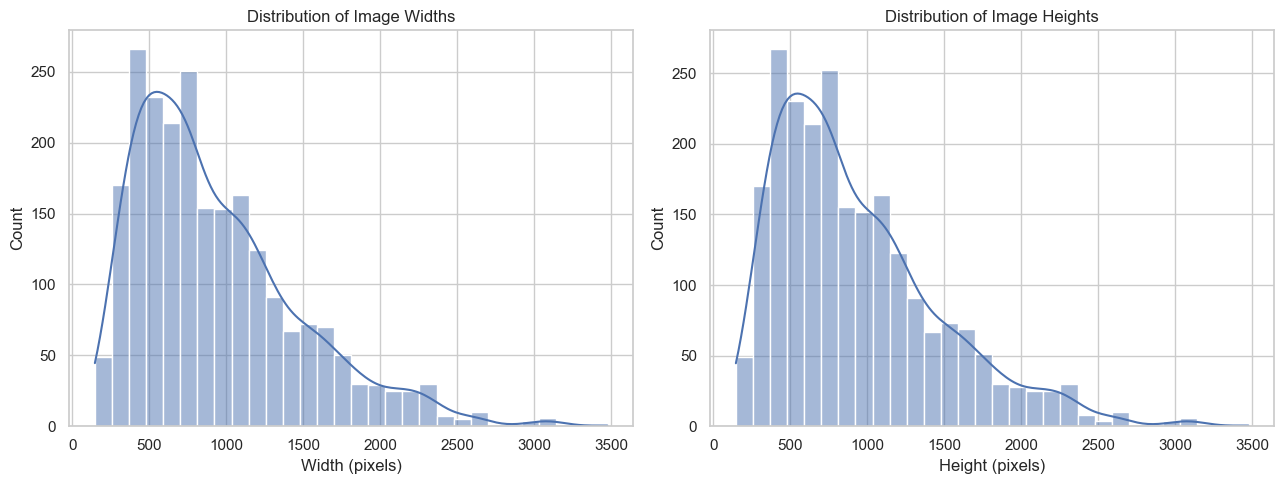

In [12]:
# Calculate image aspect ratios
image_df["aspect_ratio"] = image_df["width"] / image_df["height"]

# Display aspect ratio statistics
display(image_df["aspect_ratio"].describe())

# Plot image width and height distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    image_df["width"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Image Widths")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(
    image_df["height"],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Image Heights")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

* Implication for CNN preprocessing: We can resize images to a common resolution while preserving their aspect ratios. Since most images are already square, this should be relatively straightforward.

In [13]:
# Store brightness and contrast values
image_quality = []

for image_path in image_files:

    image = cv2.imread(str(image_path))

    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Calculate brightness and contrast
    brightness = np.mean(gray)
    contrast = np.std(gray)

    image_quality.append({
        "filename": image_path.name,
        "brightness": brightness,
        "contrast": contrast
    })

# Convert results into a DataFrame
quality_df = pd.DataFrame(image_quality)

display(quality_df.head())

,filename,brightness,contrast
0,PAT_100_393_595.png,115.565069,16.713571
1,PAT_100_393_898.png,168.416924,22.918493
2,PAT_101_1041_651.png,103.208205,14.912931
3,PAT_101_1041_658.png,98.767812,17.364047
4,PAT_101_1041_898.png,136.969008,14.761016


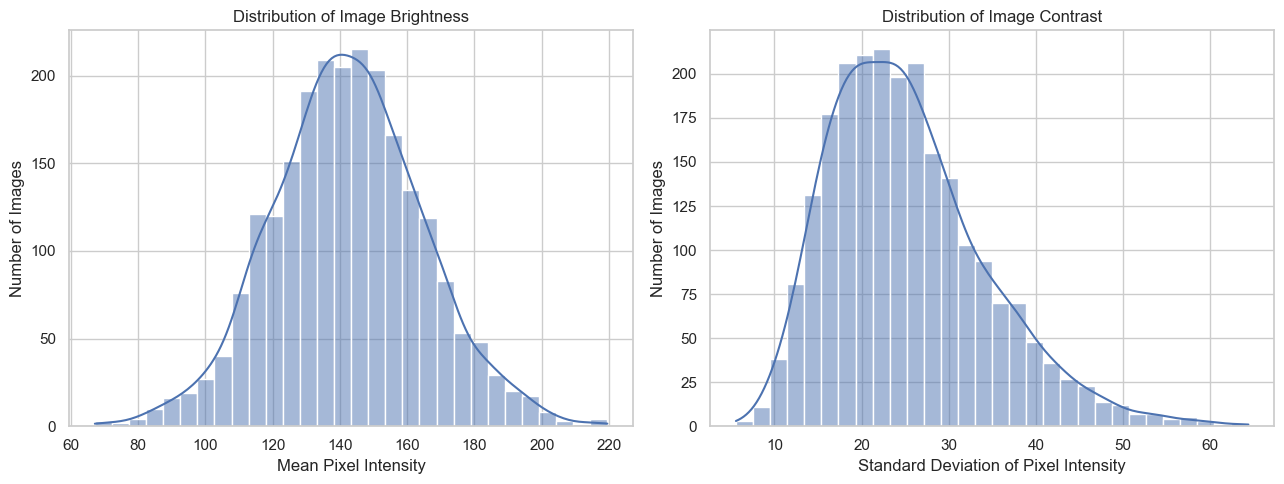

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Brightness distribution
sns.histplot(
    quality_df["brightness"],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Image Brightness")
axes[0].set_xlabel("Mean Pixel Intensity")
axes[0].set_ylabel("Number of Images")

# Contrast distribution
sns.histplot(
    quality_df["contrast"],
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Image Contrast")
axes[1].set_xlabel("Standard Deviation of Pixel Intensity")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [15]:
display(
    quality_df[["brightness", "contrast"]].describe()
)

,brightness,contrast
count,2298.000000,2298.000000
mean,142.378754,25.273900
std,22.345737,9.040785
min,67.214551,5.582341
25%,127.705446,18.680182
50%,142.187602,23.989255
75%,156.981746,30.281051
max,219.467968,64.367573


In [16]:
# Store image sharpness values
sharpness_info = []

for image_path in image_files:

    image = cv2.imread(str(image_path))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Calculate sharpness
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()

    sharpness_info.append({
        "filename": image_path.name,
        "sharpness": sharpness
    })

# Create DataFrame
sharpness_df = pd.DataFrame(sharpness_info)

display(sharpness_df.head())

,filename,sharpness
0,PAT_100_393_595.png,27.087613
1,PAT_100_393_898.png,30.521117
2,PAT_101_1041_651.png,72.362719
3,PAT_101_1041_658.png,78.629533
4,PAT_101_1041_898.png,23.418163


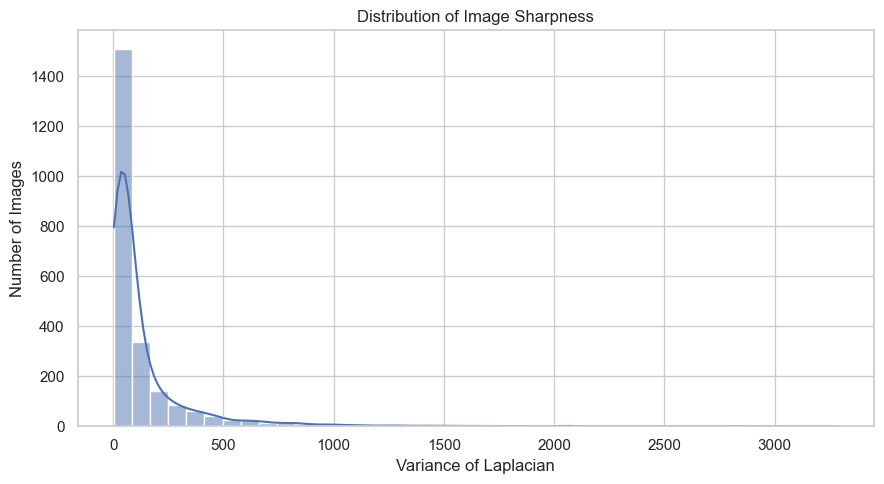

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    sharpness_df["sharpness"],
    bins=40,
    kde=True
)

plt.title("Distribution of Image Sharpness")
plt.xlabel("Variance of Laplacian")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [18]:
display(sharpness_df["sharpness"].describe())

count    2298.000000
mean      129.923762
std       223.025391
min         3.475896
25%        27.378942
50%        52.725833
75%       126.166078
max      3286.341089
Name: sharpness, dtype: float64

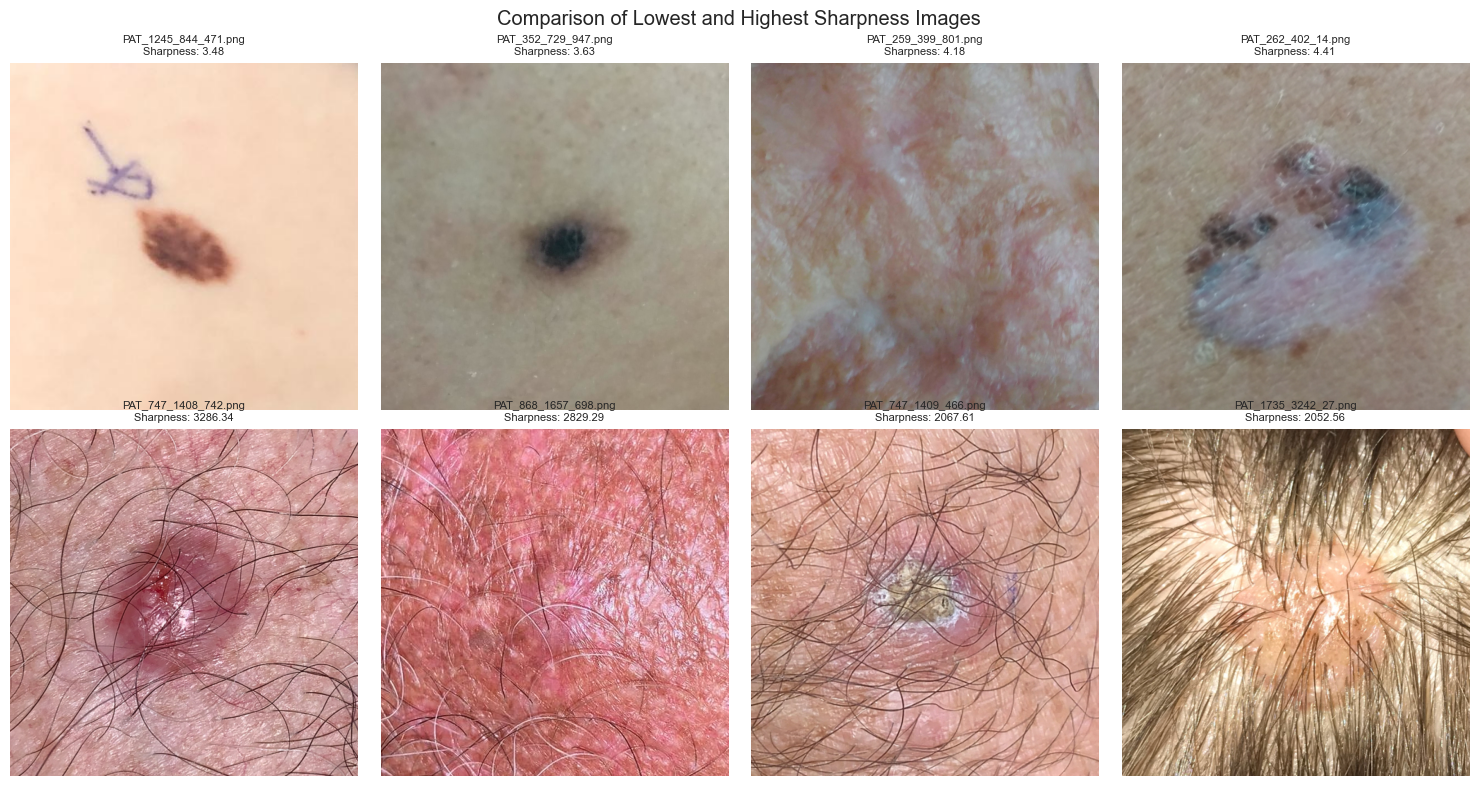

In [19]:
# Select 4 images with lowest and highest sharpness
blurriest = sharpness_df.nsmallest(4, "sharpness")
sharpest = sharpness_df.nlargest(4, "sharpness")

selected_images = pd.concat([blurriest, sharpest])

fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for ax, (_, row) in zip(axes.flatten(), selected_images.iterrows()):

    image_path = next(
        path for path in image_files
        if path.name == row["filename"]
    )

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(
        f"{row['filename']}\nSharpness: {row['sharpness']:.2f}",
        fontsize=8
    )
    ax.axis("off")

plt.suptitle("Comparison of Lowest and Highest Sharpness Images")
plt.tight_layout()
plt.show()

In [20]:
import hashlib

# Store image hashes
image_hashes = {}

for image_path in image_files:

    with open(image_path, "rb") as file:
        file_hash = hashlib.md5(file.read()).hexdigest()

    image_hashes.setdefault(file_hash, []).append(image_path)

# Identify duplicate groups
duplicate_groups = {
    file_hash: paths
    for file_hash, paths in image_hashes.items()
    if len(paths) > 1
}

# Calculate duplicate statistics
duplicate_image_count = sum(
    len(paths) - 1 for paths in duplicate_groups.values()
)

print("Total images checked:", len(image_files))
print("Unique image files:", len(image_hashes))
print("Duplicate groups:", len(duplicate_groups))
print("Number of extra duplicate copies:", duplicate_image_count)

Total images checked: 2298
Unique image files: 2283
Duplicate groups: 15
Number of extra duplicate copies: 15


In [21]:
for group_number, paths in enumerate(duplicate_groups.values(), start=1):
    print(f"\nDuplicate group {group_number}:")

    for path in paths:
        print(path.name)


Duplicate group 1:
PAT_202_307_424.png
PAT_202_308_721.png

Duplicate group 2:
PAT_302_650_477.png
PAT_302_651_529.png

Duplicate group 3:
PAT_311_666_191.png
PAT_311_667_416.png

Duplicate group 4:
PAT_38_1002_34.png
PAT_38_1003_68.png

Duplicate group 5:
PAT_38_1002_668.png
PAT_38_1003_226.png

Duplicate group 6:
PAT_419_2767_323.png
PAT_419_833_148.png

Duplicate group 7:
PAT_528_3072_615.png
PAT_528_993_589.png

Duplicate group 8:
PAT_56_86_479.png
PAT_56_88_274.png

Duplicate group 9:
PAT_570_1084_637.png
PAT_570_1085_344.png

Duplicate group 10:
PAT_570_1084_939.png
PAT_570_1085_429.png

Duplicate group 11:
PAT_691_1311_2.png
PAT_691_3994_671.png

Duplicate group 12:
PAT_691_1311_890.png
PAT_691_3994_791.png

Duplicate group 13:
PAT_701_1321_156.png
PAT_701_4056_457.png

Duplicate group 14:
PAT_759_1433_914.png
PAT_759_1538_566.png

Duplicate group 15:
PAT_834_1572_430.png
PAT_834_1574_276.png


In [22]:
metadata_df = pd.read_csv(CSV_PATH)

print("CSV shape:", metadata_df.shape)
print("\nColumn names:")
print(metadata_df.columns.tolist())

display(metadata_df.head())

CSV shape: (2298, 26)

Column names:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,cancer_history,has_piped_water,has_sewage_system,fitspatrick,region,diameter_1,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ARM,NaN,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,True,True,True,3.0,NECK,6.0,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FACE,NaN,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HAND,NaN,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,False,False,False,1.0,FOREARM,5.0,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True


In [23]:
# Count images in each diagnosis class
class_counts = metadata_df["diagnostic"].value_counts()

# Calculate percentage of the dataset in each class
class_percentages = (
    metadata_df["diagnostic"]
    .value_counts(normalize=True)
    .mul(100)
)

# Combine counts and percentages into one table
class_distribution = pd.DataFrame({
    "image_count": class_counts,
    "percentage": class_percentages.round(2)
})

display(class_distribution)

print("Number of diagnosis classes:", metadata_df["diagnostic"].nunique())
print("Missing diagnosis labels:", metadata_df["diagnostic"].isna().sum())
print("Missing image filenames:", metadata_df["img_id"].isna().sum())

,image_count,percentage
diagnostic,,
BCC,845,36.77
ACK,730,31.77
NEV,244,10.62
SEK,235,10.23
SCC,192,8.36
MEL,52,2.26


Number of diagnosis classes: 6
Missing diagnosis labels: 0
Missing image filenames: 0


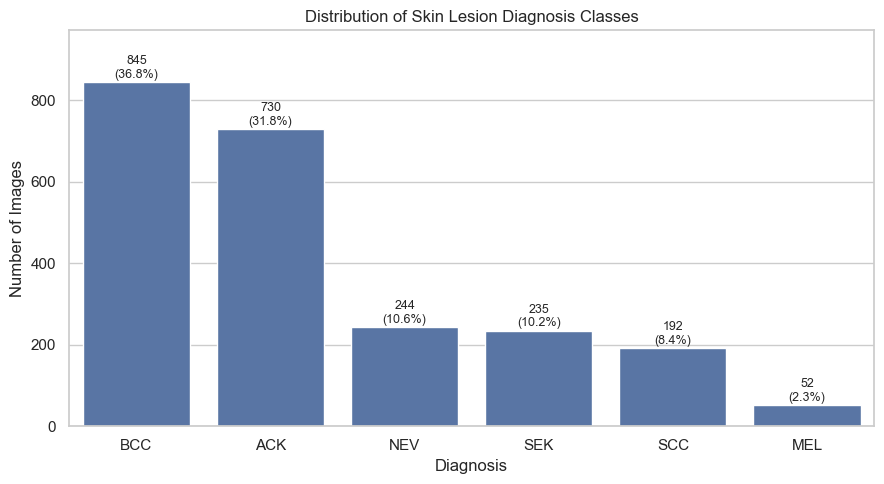

In [24]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Skin Lesion Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")

# Display count and percentage above each bar
for i, (count, percentage) in enumerate(
    zip(class_counts.values, class_percentages.values)
):
    ax.text(
        i,
        count + 10,
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        fontsize=9
    )

plt.ylim(0, max(class_counts.values) * 1.15)
plt.tight_layout()
plt.show()

The PAD-UFES-20 dataset contains six diagnosis classes, with no missing diagnosis labels. However, the class distribution is imbalanced. BCC (36.77%) and ACK (31.77%) are the most represented classes, while MEL accounts for only 2.26% of the images. This imbalance may affect the CNN's ability to learn minority classes effectively. Therefore, evaluation will include macro-F1, per-class precision and recall, and a confusion matrix in addition to accuracy. Class weighting will also be considered during model training.

In [25]:
print("Total image records:", len(metadata_df))

print("Unique patients:", metadata_df["patient_id"].nunique())

print("Unique lesions:", metadata_df["lesion_id"].nunique())

print("\nImages per patient:")
print(metadata_df.groupby("patient_id")["img_id"].count().describe())

print("\nImages per lesion:")
print(metadata_df.groupby("lesion_id")["img_id"].count().describe())

Total image records: 2298
Unique patients: 1373
Unique lesions: 1641

Images per patient:
count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
Name: img_id, dtype: float64

Images per lesion:
count    1641.000000
mean        1.400366
std         0.686081
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: img_id, dtype: float64


Key observations
Patient level
- There are 1,373 unique patients for 2,298 image records.
- Each patient has an average of approximately 1.67 images.
- Some patients have up to 10 images.
Lesion level
- There are 1,641 unique lesions.
- Each lesion has an average of approximately 1.4 images.
- Some lesions have up to 8 images.
This means the dataset contains multiple images of certain patients and lesions.

**EDA CONCLUSION**
- Exploratory Data Analysis was performed on the PAD-UFES-20 image dataset, consisting of 2,298 images across three image folders.
- All images were successfully loaded, with no unreadable files detected. Image dimensions varied considerably, although most images had approximately square aspect ratios.
- Brightness, contrast and sharpness measurements revealed variation in image characteristics.
- Exact duplicate detection identified 15 duplicate pairs, leaving 2,283 unique image files.

- The dataset contains six diagnostic classes with an imbalanced distribution. 
- BCC and ACK represent the largest classes, accounting for 36.77% and 31.77% respectively, while MEL represents only 2.26%. 
- Furthermore, the 2,298 image records correspond to 1,373 unique patients and 1,641 unique lesions, indicating that multiple images may belong to the same patient or lesion. 
- These findings will inform the preprocessing, class imbalance handling and patient-level data splitting strategies used during model development.

In [26]:
# Create a dataframe containing image filenames and diagnosis labels

image_labels_df = metadata_df[["img_id", "diagnostic"]].copy()

# Create a lookup dictionary: filename -> image path
image_path_lookup = {
    image_path.name: image_path
    for image_path in image_files
}

# Match each CSV filename to its actual image path
image_labels_df["image_path"] = image_labels_df["img_id"].map(
    image_path_lookup
)

# Keep only records where the image file exists
image_labels_df = image_labels_df.dropna(
    subset=["image_path"]
).copy()

print("Images matched with diagnosis labels:", len(image_labels_df))
display(image_labels_df.head())

Images matched with diagnosis labels: 2298


,img_id,diagnostic,image_path
0,PAT_1516_1765_530.png,NEV,C:\Users\Kanakan\Skin Lesion Classification\PA...
1,PAT_46_881_939.png,BCC,C:\Users\Kanakan\Skin Lesion Classification\PA...
2,PAT_1545_1867_547.png,ACK,C:\Users\Kanakan\Skin Lesion Classification\PA...
3,PAT_1989_4061_934.png,ACK,C:\Users\Kanakan\Skin Lesion Classification\PA...
4,PAT_684_1302_588.png,BCC,C:\Users\Kanakan\Skin Lesion Classification\PA...


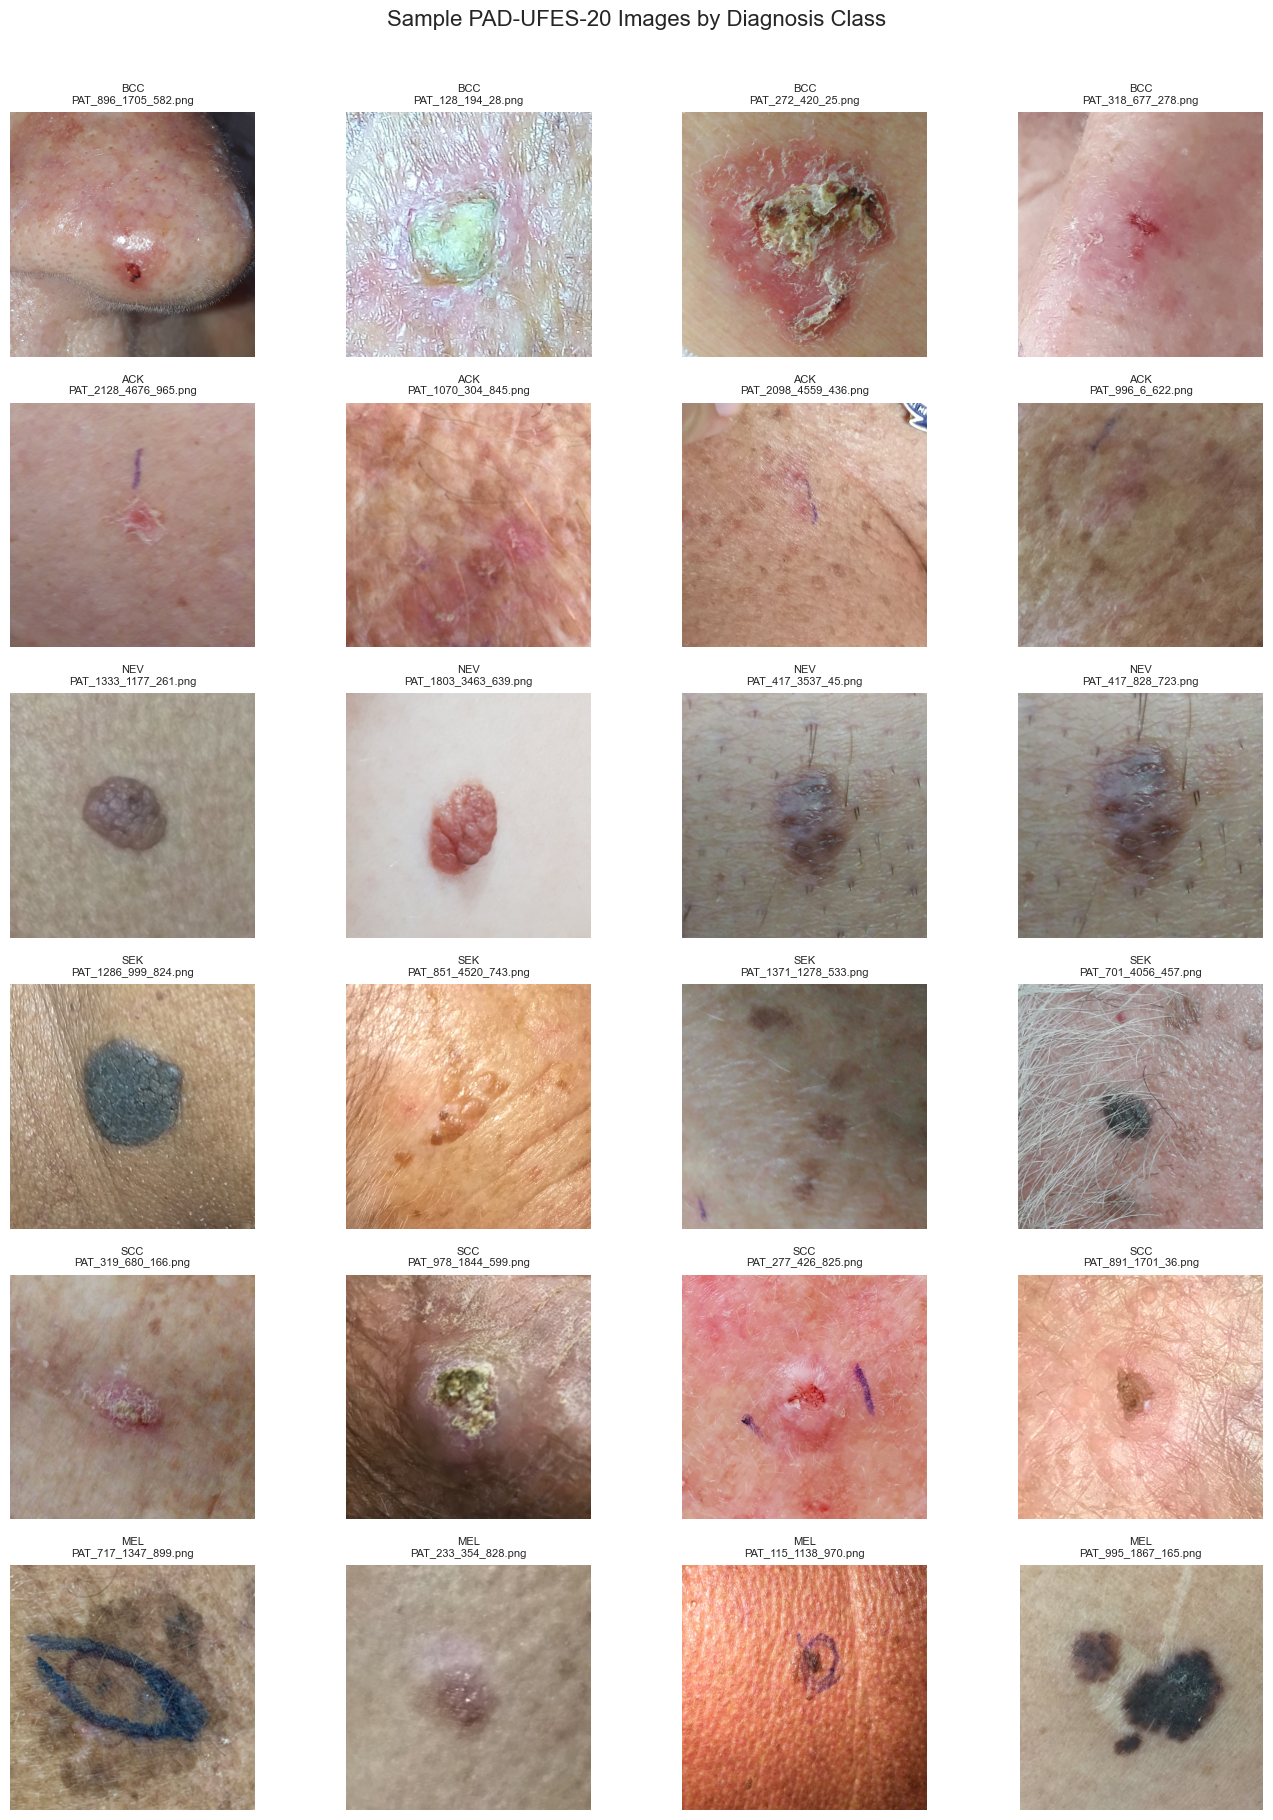

In [27]:
# Define the diagnosis classes in the order we want to display them
diagnosis_classes = ["BCC", "ACK", "NEV", "SEK", "SCC", "MEL"]

# Number of images to display per class
images_per_class = 4

# Use a fixed random seed so the same samples can be reproduced
rng = np.random.default_rng(42)

# Create a grid with 6 rows and 4 columns
fig, axes = plt.subplots(
    nrows=len(diagnosis_classes),
    ncols=images_per_class,
    figsize=(14, 18)
)

for row, diagnosis in enumerate(diagnosis_classes):

    # Select records belonging to the current diagnosis
    class_images = image_labels_df[
        image_labels_df["diagnostic"] == diagnosis
    ]

    # Randomly select up to 4 images
    sample_size = min(images_per_class, len(class_images))

    sampled_images = class_images.sample(
        n=sample_size,
        random_state=42
    )

    for col in range(images_per_class):

        ax = axes[row, col]

        if col < sample_size:

            image_path = sampled_images.iloc[col]["image_path"]

            # Read image
            image = cv2.imread(str(image_path))

            # Convert BGR to RGB for correct display
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            ax.imshow(image)
            ax.set_title(
                f"{diagnosis}\n{image_path.name}",
                fontsize=8
            )

        else:
            ax.set_visible(False)

        ax.axis("off")

plt.suptitle(
    "Sample PAD-UFES-20 Images by Diagnosis Class",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [28]:
# Combine brightness and contrast information
image_features_df = quality_df.merge(
    sharpness_df,
    on="filename",
    how="inner"
)

# Match image characteristics with diagnosis labels
image_features_df = image_features_df.merge(
    metadata_df[["img_id", "diagnostic"]],
    left_on="filename",
    right_on="img_id",
    how="inner"
)

# Remove the extra filename column
image_features_df = image_features_df.drop(columns=["img_id"])

print("Total matched images:", len(image_features_df))

display(image_features_df.head())

Total matched images: 2298


,filename,brightness,contrast,sharpness,diagnostic
0,PAT_100_393_595.png,115.565069,16.713571,27.087613,NEV
1,PAT_100_393_898.png,168.416924,22.918493,30.521117,NEV
2,PAT_101_1041_651.png,103.208205,14.912931,72.362719,BCC
3,PAT_101_1041_658.png,98.767812,17.364047,78.629533,BCC
4,PAT_101_1041_898.png,136.969008,14.761016,23.418163,BCC


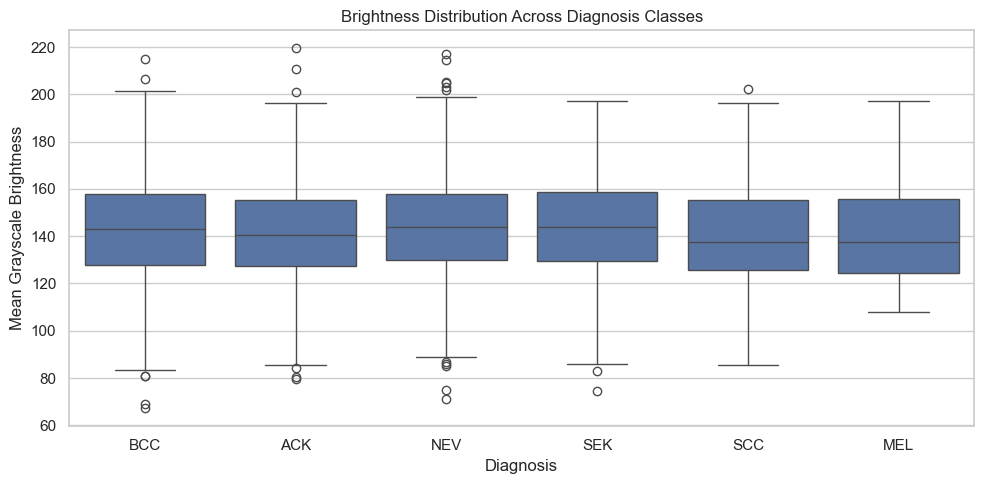

In [29]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=image_features_df,
    x="diagnostic",
    y="brightness",
    order=diagnosis_classes
)

plt.title("Brightness Distribution Across Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Grayscale Brightness")

plt.tight_layout()
plt.show()

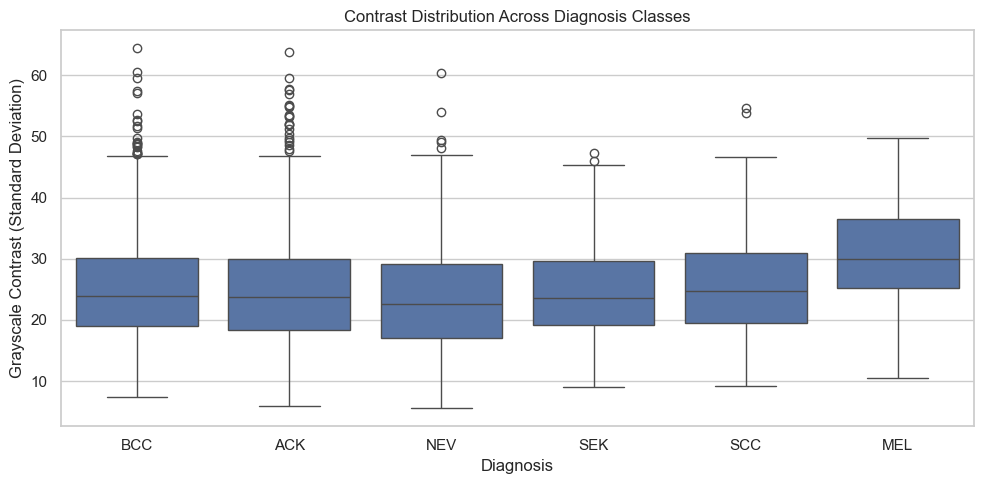

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=image_features_df,
    x="diagnostic",
    y="contrast",
    order=diagnosis_classes
)

plt.title("Contrast Distribution Across Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Grayscale Contrast (Standard Deviation)")

plt.tight_layout()
plt.show()

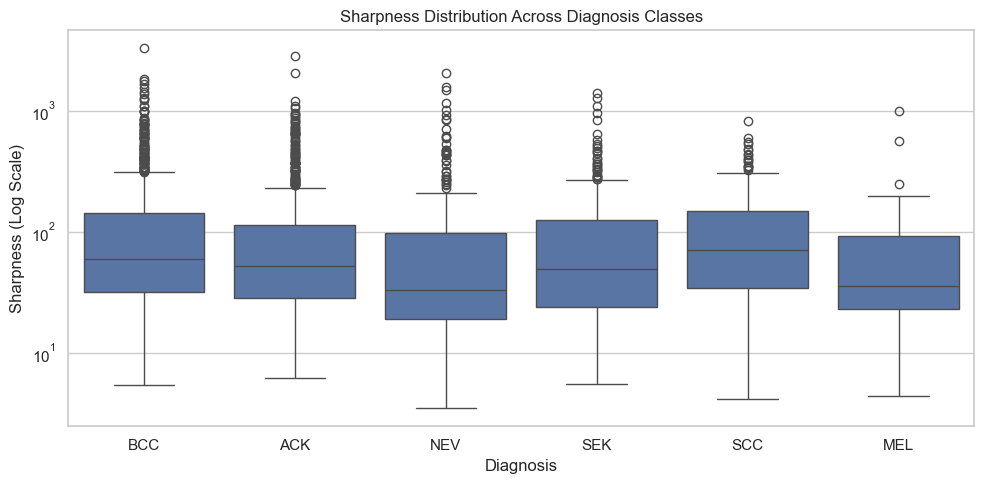

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=image_features_df,
    x="diagnostic",
    y="sharpness",
    order=diagnosis_classes
)

plt.yscale("log")

plt.title("Sharpness Distribution Across Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Sharpness (Log Scale)")

plt.tight_layout()
plt.show()

In [32]:
# Calculate mean, median and standard deviation
class_feature_summary = (
    image_features_df
    .groupby("diagnostic")[
        ["brightness", "contrast", "sharpness"]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(class_feature_summary)

brightness                contrast              sharpness         \
                 mean  median    std     mean median   std      mean median   
diagnostic                                                                    
ACK            141.07  140.70  21.19    25.20  23.73  9.47    119.50  51.75   
BCC            142.76  142.94  22.39    25.28  23.97  8.72    148.85  59.81   
MEL            140.64  137.67  20.98    30.15  29.96  8.85     86.54  35.47   
NEV            144.49  144.07  24.43    24.39  22.58  9.46    123.44  32.98   
SCC            141.18  137.60  22.96    25.83  24.69  8.95    119.51  70.13   
SEK            144.23  143.99  23.08    24.86  23.62  8.15    119.08  49.15   

                    
               std  
diagnostic          
ACK         208.13  
BCC         251.47  
MEL         158.02  
NEV         253.33  
SCC         129.00  
SEK         192.97

In [33]:
# Get all image filenames from the image folders
image_filenames = {path.name for path in image_files}

# Get all image filenames recorded in the CSV
csv_filenames = set(metadata_df["img_id"].dropna())

# Images that exist in folders but not in the CSV
images_without_csv_record = image_filenames - csv_filenames

# CSV records that do not have a corresponding image
csv_records_without_image = csv_filenames - image_filenames

# Check whether any filenames appear more than once in the CSV
duplicate_csv_filenames = metadata_df[
    metadata_df["img_id"].duplicated(keep=False)
]

# Check for missing diagnosis labels
missing_diagnoses = metadata_df[
    metadata_df["diagnostic"].isna()
]

print("Total image files:", len(image_filenames))
print("Total unique CSV image filenames:", len(csv_filenames))

print("\nImages without CSV records:", len(images_without_csv_record))
print("CSV records without image files:", len(csv_records_without_image))
print("Repeated image filenames in CSV:", len(duplicate_csv_filenames))
print("Missing diagnosis labels:", len(missing_diagnoses))

Total image files: 2298
Total unique CSV image filenames: 2298

Images without CSV records: 0
CSV records without image files: 0
Repeated image filenames in CSV: 0
Missing diagnosis labels: 0


In [34]:
# Store information about each duplicate pair
duplicate_label_results = []

for group_number, paths in enumerate(
    duplicate_groups.values(),
    start=1
):

    # Retrieve CSV records for the duplicate filenames
    duplicate_records = metadata_df[
        metadata_df["img_id"].isin(
            [path.name for path in paths]
        )
    ]

    # Extract diagnosis labels
    diagnoses = duplicate_records["diagnostic"].dropna().unique()

    # Determine whether the labels match
    if len(diagnoses) == 1:
        label_status = "Same diagnosis"
    elif len(diagnoses) > 1:
        label_status = "Different diagnoses"
    else:
        label_status = "Missing diagnosis"

    # Store the results
    duplicate_label_results.append({
        "duplicate_group": group_number,
        "filenames": ", ".join(path.name for path in paths),
        "patient_ids": ", ".join(
            duplicate_records["patient_id"].astype(str).unique()
        ),
        "lesion_ids": ", ".join(
            duplicate_records["lesion_id"].astype(str).unique()
        ),
        "diagnoses": ", ".join(diagnoses),
        "label_status": label_status
    })

# Convert results into a dataframe
duplicate_label_df = pd.DataFrame(duplicate_label_results)

display(duplicate_label_df)

,duplicate_group,filenames,patient_ids,lesion_ids,diagnoses,label_status
0,1,"PAT_202_307_424.png, PAT_202_308_721.png",PAT_202,"307, 308","BCC, ACK",Different diagnoses
1,2,"PAT_302_650_477.png, PAT_302_651_529.png",PAT_302,"651, 650","BCC, SCC",Different diagnoses
2,3,"PAT_311_666_191.png, PAT_311_667_416.png",PAT_311,"666, 667","SCC, BCC",Different diagnoses
3,4,"PAT_38_1002_34.png, PAT_38_1003_68.png",PAT_38,"1002, 1003","BCC, ACK",Different diagnoses
4,5,"PAT_38_1002_668.png, PAT_38_1003_226.png",PAT_38,"1003, 1002","ACK, BCC",Different diagnoses
5,6,"PAT_419_2767_323.png, PAT_419_833_148.png",PAT_419,"2767, 833","ACK, SCC",Different diagnoses
6,7,"PAT_528_3072_615.png, PAT_528_993_589.png",PAT_528,"3072, 993",ACK,Same diagnosis
7,8,"PAT_56_86_479.png, PAT_56_88_274.png",PAT_56,"86, 88","SCC, BCC",Different diagnoses
8,9,"PAT_570_1084_637.png, PAT_570_1085_344.png",PAT_570,"1084, 1085","SCC, BCC",Different diagnoses
9,10,"PAT_570_1084_939.png, PAT_570_1085_429.png",PAT_570,"1085, 1084","BCC, SCC",Different diagnoses


In [35]:
print("Total duplicate groups:", len(duplicate_label_df))

print("\nDuplicate label consistency:")
print(
    duplicate_label_df["label_status"]
    .value_counts()
)

print("\nDuplicate groups with different diagnoses:")

display(
    duplicate_label_df[
        duplicate_label_df["label_status"] == "Different diagnoses"
    ]
)

Total duplicate groups: 15

Duplicate label consistency:
label_status
Different diagnoses    12
Same diagnosis          3
Name: count, dtype: int64

Duplicate groups with different diagnoses:


,duplicate_group,filenames,patient_ids,lesion_ids,diagnoses,label_status
0,1,"PAT_202_307_424.png, PAT_202_308_721.png",PAT_202,"307, 308","BCC, ACK",Different diagnoses
1,2,"PAT_302_650_477.png, PAT_302_651_529.png",PAT_302,"651, 650","BCC, SCC",Different diagnoses
2,3,"PAT_311_666_191.png, PAT_311_667_416.png",PAT_311,"666, 667","SCC, BCC",Different diagnoses
3,4,"PAT_38_1002_34.png, PAT_38_1003_68.png",PAT_38,"1002, 1003","BCC, ACK",Different diagnoses
4,5,"PAT_38_1002_668.png, PAT_38_1003_226.png",PAT_38,"1003, 1002","ACK, BCC",Different diagnoses
5,6,"PAT_419_2767_323.png, PAT_419_833_148.png",PAT_419,"2767, 833","ACK, SCC",Different diagnoses
7,8,"PAT_56_86_479.png, PAT_56_88_274.png",PAT_56,"86, 88","SCC, BCC",Different diagnoses
8,9,"PAT_570_1084_637.png, PAT_570_1085_344.png",PAT_570,"1084, 1085","SCC, BCC",Different diagnoses
9,10,"PAT_570_1084_939.png, PAT_570_1085_429.png",PAT_570,"1085, 1084","BCC, SCC",Different diagnoses
10,11,"PAT_691_1311_2.png, PAT_691_3994_671.png",PAT_691,"3994, 1311","ACK, BCC",Different diagnoses


Additional EDA Findings and Interpretation
1. Diagnosis-wise Image Visualisation
- Four sample images were visualised for each of the six diagnostic classes.
- Images showed visual variations within and between classes.
- Some classes share similar visual characteristics, highlighting the challenge of image classification.
2. Image Characteristics by Diagnosis
- Brightness: Mean values were similar across classes (140.64-144.49).
- Contrast: MEL had the highest mean (30.15), while NEV had the lowest (24.39).
- Sharpness: BCC had the highest mean (148.85), while MEL had the lowest (86.54).
- Large within-class variations were observed, so these metrics are not reliable diagnostic indicators.
3. Image-to-Label Mapping Verification
- Total images: 2,298.
- Images without metadata records: 0.
- Metadata records without images: 0.
- Repeated filenames in metadata: 0.
- Missing diagnostic labels: 0.
- All images were successfully matched with their metadata records and labels.
4. Duplicate Image Investigation
- MD5 hashing identified 15 duplicate groups (15 additional copies).
- Unique image files: 2,283.
- 12 groups had conflicting diagnostic labels.
- 3 groups had matching diagnostic labels.
- Duplicate records shared patient IDs but had different lesion IDs.
- Identical images with conflicting labels may introduce ambiguity during CNN training.
- No records have been removed; further investigation is required before cleaning.
5. Overall Image EDA Summary
- All 2,298 images were successfully loaded.
- Images were predominantly square.
- Brightness, contrast and sharpness varied across images.
- The dataset showed substantial class imbalance, particularly for MEL (2.26%).
- All images were successfully matched to metadata and diagnostic labels.
- CNNs will automatically learn image features during training.
6. Considerations for Model Development
- Class imbalance: Consider class weights or other balancing techniques.
- Evaluation: Use macro-F1, per-class recall and confusion matrices alongside accuracy.
- Duplicates: Finalise a suitable handling strategy before training.
- Data splitting: Use patient-level splitting to prevent data leakage.
- Clustering: Optional extension; encouraged but not compulsory.